MINi project ML
# Explainable AI  for Loan Approval Decisions

This is my mini project. The idea is simple :- Banks use ML to decide if a loan should be
approved or not, but models like random forest dont tell us WHY they said no.
So here I train a few models on the loan prediction dataset and then use SHAP and LIME
to explain the decisions.

dataset = train.csv (614 rows, from the analytics vidhya loan prediction problem)
test.csv is also there, I use it at the end to predict for new customers.

## Problem statement and objectives

**problem** - banks get thousands of loan applications and now ML models decide approve/reject.
models like random forest are accurate but they are a black box - if a customer gets rejected
nobody can say "WHY ?". in banking that is a problem because the customer has a right to know,
and the bank also has to be able to justify the decision.

**objectives**
1. do the EDA and preprocessing on the loan prediction dataset (missing values, encoding)
2. train and compare 4 models - logistic regression, decision tree, SVM, random forest
3. evaluate with accuracy, precision, recall and F1 (not only accuracy, because the data is imbalanced)
4. use SHAP and LIME to explain the model globally (which features matter) and locally (why this one customer)
5. build a small working prototype that takes a new customer's details and prints the decision + top reasons
6. predict the unlabeled test.csv customers as a final demo

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 

In [2]:
data = pd.read_csv("train.csv")

In [3]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

#import shap
#import lime
#import lime.lime_tabular

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


Check Shape and Missing Values

In [7]:
data.apply(lambda x: sum(x.isnull()),axis=0) # checking missing values in each column of train dataset)

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
data['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

# Visualize how different features affect the 'Loan_Status'

/var/folders/27/q8cl31154vs3yxnx5ctf4kg40000gn/T/ipykernel_2598/1595846495.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Loan_Status',data=data,palette='Set2')


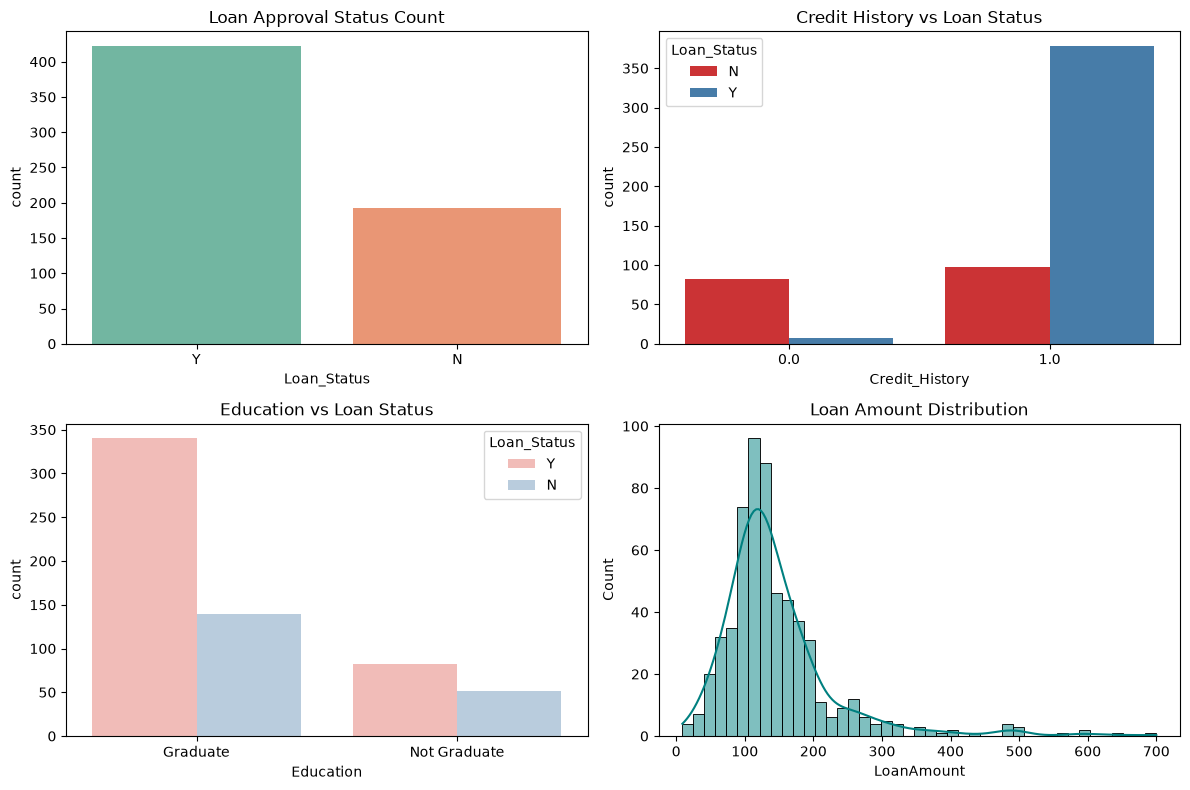

In [9]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.countplot(x='Loan_Status',data=data,palette='Set2')
plt.title('Loan Approval Status Count')
 #2. Credit History vs Loan Status
plt.subplot(2, 2, 2)
sns.countplot(x='Credit_History', hue='Loan_Status',data=data,palette='Set1')
plt.title('Credit History vs Loan Status')
#3. Education vs Loan Status
plt.subplot(2, 2, 3)
sns.countplot(x='Education', hue='Loan_Status',data=data,palette='Pastel1')
plt.title('Education vs Loan Status')
#4. Loan Amount Distribution
plt.subplot(2, 2, 4)
sns.histplot(data['LoanAmount'].dropna(),kde=True,color='teal')
plt.title('Loan Amount Distribution')
plt.tight_layout()
plt.show()

so from the plots - most people got the loan (Y is more than N), credit history = 1 people
get approved almost always, graduates are a bit better than non graduates, and loan amount
is skewed to the right (few people asking very big loans).

##  Data Cleaning and Handling  Missing Values from the dataset

In [10]:
data.Gender = data.Gender.fillna('Male')
data['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [11]:
data.Married = data.Married.fillna('Yes')
data['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [12]:
data.Dependents = data.Dependents.fillna('0')
data['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [13]:
data.Self_Employed=data.Self_Employed.fillna('No')
data.LoanAmount=data.LoanAmount.fillna(data.LoanAmount.mean())
data['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [14]:
data.Loan_Amount_Term=data.Loan_Amount_Term.fillna(360.0)
data['Credit_History'].value_counts()

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [15]:
data.Credit_History=data.Credit_History.fillna(1.0)
data.apply(lambda x: sum(x.isnull()),axis=0)

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [16]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y


In [17]:
data = data.drop('Loan_ID', axis=1)
X = data.iloc[:, 0:11]
y = data.iloc[:, 11]
X.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,Male,No,0,Graduate,No,5849,0.0,146.412162,360.0,1.0,Urban
1,Male,Yes,1,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban
4,Male,No,0,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban


In [18]:
y

0      Y
1      N
2      Y
3      Y
4      Y
      ..
609    Y
610    Y
611    Y
612    Y
613    N
Name: Loan_Status, Length: 614, dtype: str

In [19]:
# Drop ID columns if present
if 'Loan_ID' in data.columns:
    data = data.drop('Loan_ID', axis=1)
if 'Unnamed: 0' in data.columns:
    data = data.drop('Unnamed: 0', axis=1)
# Fill categorical missing values with Mode
data['Gender'] = data['Gender'].fillna(data['Gender'].mode()[0])
data['Married'] = data['Married'].fillna(data['Married'].mode()[0])
data['Dependents'] = data['Dependents'].fillna(data['Dependents'].mode()[0])
data['Self_Employed'] = data['Self_Employed'].fillna(data['Self_Employed'].mode()[0])
data['Credit_History'] = data['Credit_History'].fillna(data['Credit_History'].mode()[0])
# Fill numerical missing values with Median
data['LoanAmount'] = data['LoanAmount'].fillna(data['LoanAmount'].median())
data['Loan_Amount_Term'] = data['Loan_Amount_Term'].fillna(data['Loan_Amount_Term'].median())
# Verify that no missing values remain
print("Remaining Missing Values:\n", data.isnull().sum())

Remaining Missing Values:
 Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


### encoding the text columns

models only understand numbers so Gender, Married etc have to be converted.
Dependents has '3+' in it which is text, so I make it 3.

In [20]:
data['Dependents'] = data['Dependents'].replace('3+', 3).astype(int)

data['Gender'] = data['Gender'].map({'Male':1, 'Female':0})
data['Married'] = data['Married'].map({'Yes':1, 'No':0})
data['Education'] = data['Education'].map({'Graduate':1, 'Not Graduate':0})
data['Self_Employed'] = data['Self_Employed'].map({'Yes':1, 'No':0})
data['Property_Area'] = data['Property_Area'].map({'Rural':0, 'Semiurban':1, 'Urban':2})
data['Loan_Status'] = data['Loan_Status'].map({'Y':1, 'N':0})   # Y = approved

data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,1,0,5849,0.0,146.412162,360.0,1.0,2,1
1,1,1,1,1,0,4583,1508.0,128.000000,360.0,1.0,0,0
2,1,1,0,1,1,3000,0.0,66.000000,360.0,1.0,2,1
3,1,1,0,0,0,2583,2358.0,120.000000,360.0,1.0,2,1
4,1,0,0,1,0,6000,0.0,141.000000,360.0,1.0,2,1


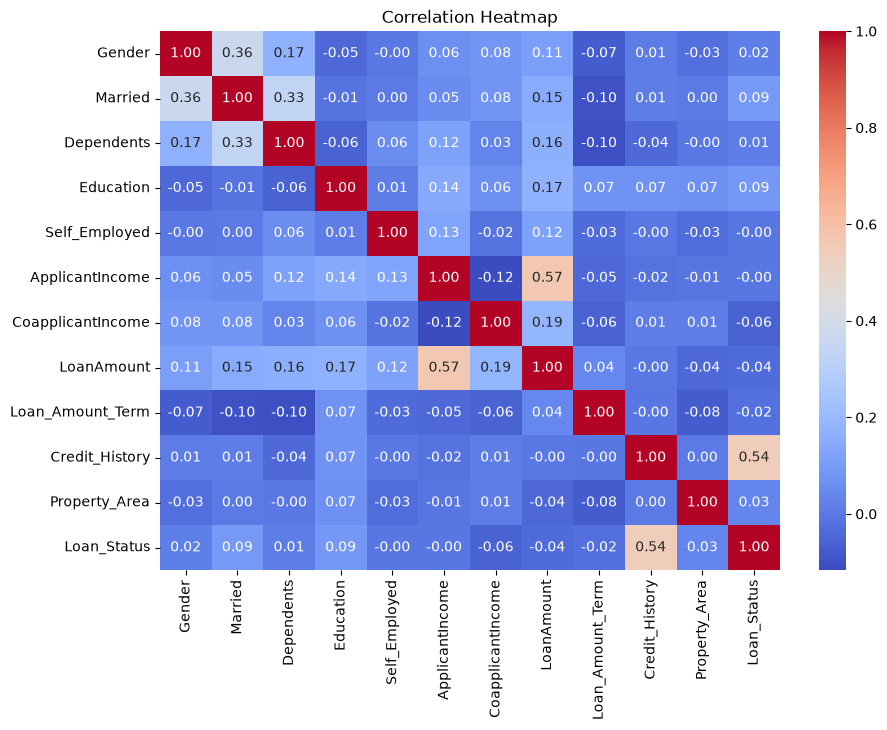

In [21]:
# which features are related to each other
plt.figure(figsize=(10,7))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### Train test split

80% for training and 20% for testing. scaling is done only for logistic regression and SVM
because they use distances, trees dont need it. I keep the unscaled data for SHAP/LIME so
the explanations show real income and loan amount values.

In [22]:
X = data.drop('Loan_Status', axis=1)
y = data['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (491, 11)
Testing set size: (123, 11)


## Trying the models

4 models - logistic regression, decision tree, SVM and random forest.

In [23]:
# 1. logistic regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

# 2. decision tree
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# 3. SVM
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)

# 4. random forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("all 4 models trained")

all 4 models trained


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [24]:
from sklearn.metrics import confusion_matrix, classification_report


rows = []
for name, pred in [('Logistic Regression', lr_pred), ('Decision Tree', dt_pred),
                   ('SVM', svm_pred), ('Random Forest', rf_pred)]:
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'F1-Score': round(f1_score(y_test, pred), 4)
    })

results = pd.DataFrame(rows)
results.to_csv('results.csv', index=False)   # saving so I can put it in the report
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8618,0.8400,0.9882,0.9081
1,Decision Tree,0.8455,0.8235,0.9882,0.8984
2,SVM,0.8537,0.8317,0.9882,0.9032
3,Random Forest,0.8455,0.8235,0.9882,0.8984


/var/folders/27/q8cl31154vs3yxnx5ctf4kg40000gn/T/ipykernel_2598/1691925167.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results, palette='viridis')


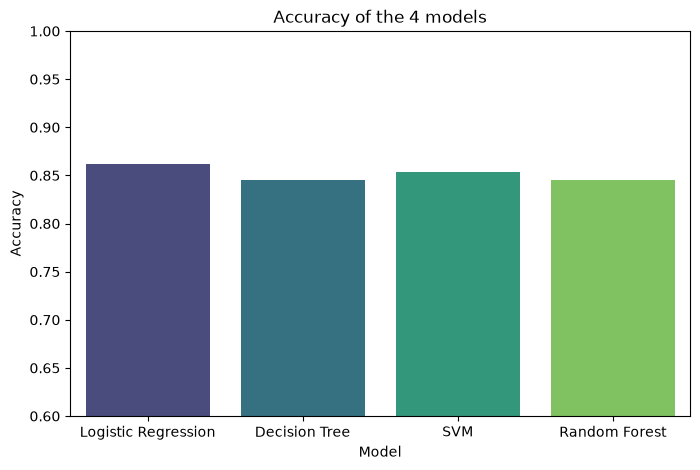

In [25]:
plt.figure(figsize=(8,5))
sns.barplot(x='Model', y='Accuracy', data=results, palette='viridis')
plt.ylim(0.6, 1.0)
plt.title('Accuracy of the 4 models')
plt.ylabel('Accuracy')
plt.show()

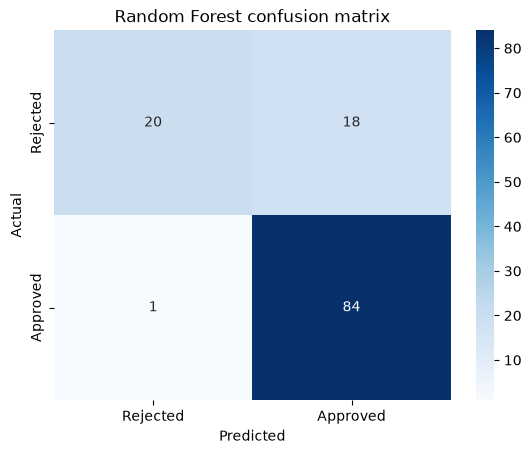

              precision    recall  f1-score   support

    Rejected       0.95      0.53      0.68        38
    Approved       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



In [26]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected','Approved'], yticklabels=['Rejected','Approved'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest confusion matrix')
plt.show()

print(classification_report(y_test, rf_pred, target_names=['Rejected','Approved']))

## Explainable AI part

random forest is 100 trees so we cant read it. Three things here -
1. decision tree plot (this one we CAN read)
2. SHAP - which features matter overall + one customer
3. LIME - one customer again, to check SHAP is not lying

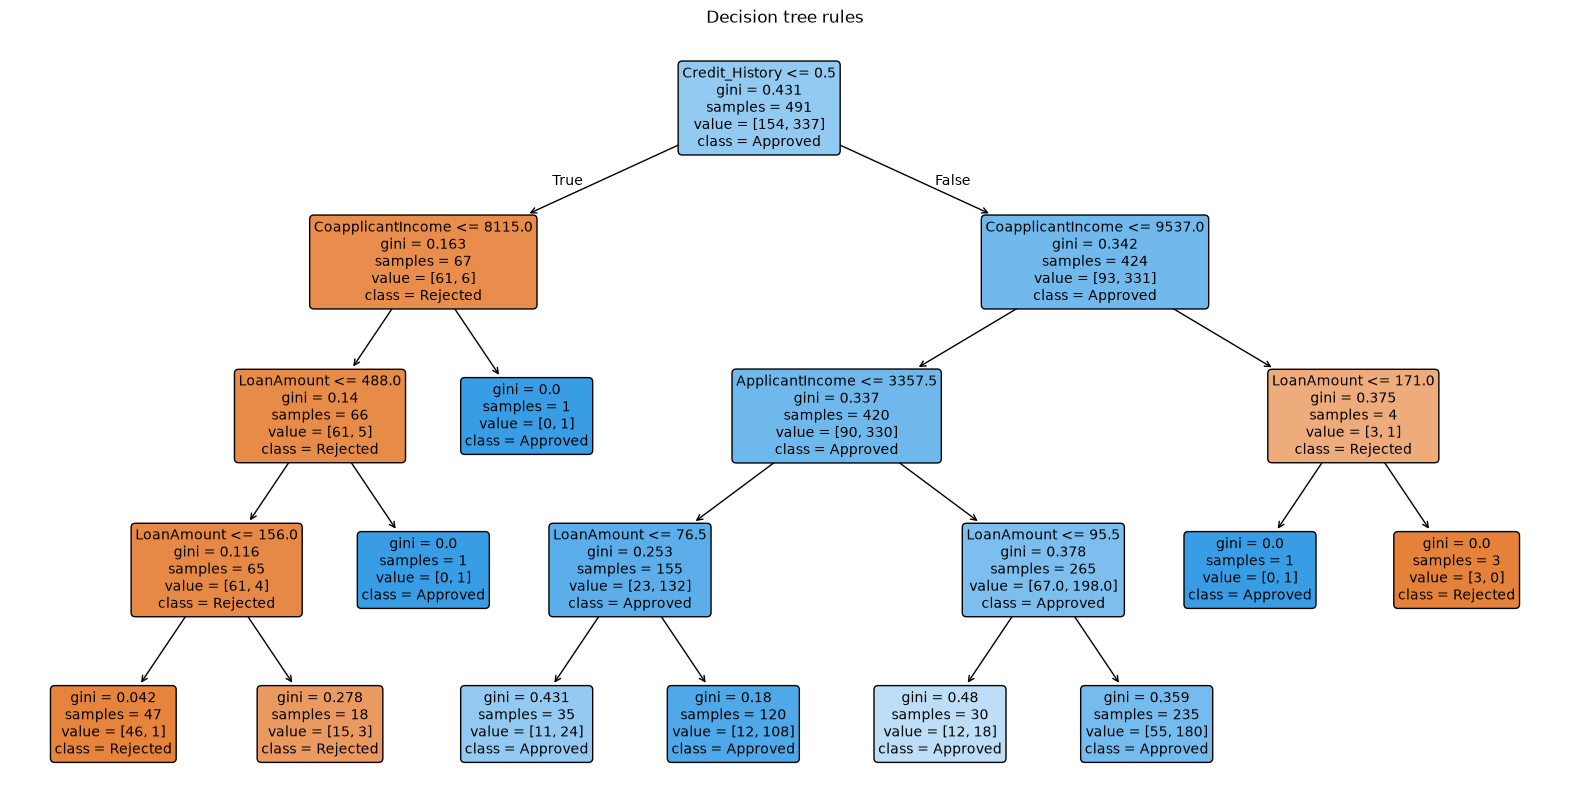

In [27]:
plt.figure(figsize=(20,10))
plot_tree(dt_model, feature_names=X.columns, class_names=['Rejected','Approved'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision tree rules')
plt.show()

### SHAP

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


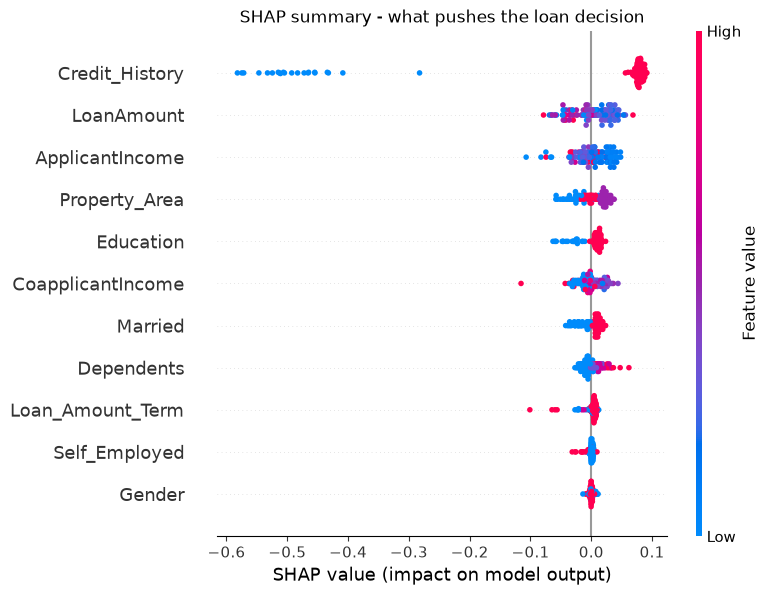

In [28]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# shap gives values for both classes, we want class 1 (approved)
if len(shap_values.shape) == 3:
    shap_values_approved = shap_values[:, :, 1]
else:
    shap_values_approved = shap_values

shap.summary_plot(shap_values_approved, X_test, show=False)
plt.title('SHAP summary - what pushes the loan decision')
plt.show()

how to read this - top feature is the most important one. red dot = high value of that
feature, blue = low. if the red dots are on the right side it means high value pushes
towards approval. credit history is clearly the biggest thing here, way bigger than
income or loan amount.

customer number 0
Gender                  1.0
Married                 0.0
Dependents              0.0
Education               1.0
Self_Employed           0.0
ApplicantIncome      6277.0
CoapplicantIncome       0.0
LoanAmount            118.0
Loan_Amount_Term      360.0
Credit_History          0.0
Property_Area           0.0
Name: 150, dtype: float64
prediction: 0 (1 = approved, 0 = rejected)


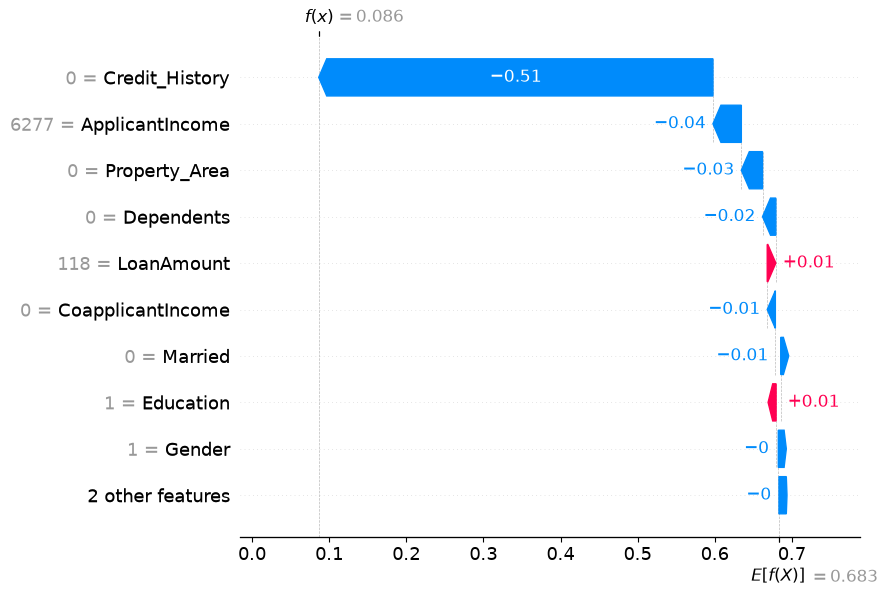

In [29]:
# now explain ONE customer from the test set
i = 0
print("customer number", i)
print(X_test.iloc[i])
print("prediction:", rf_pred[i], "(1 = approved, 0 = rejected)")

shap.plots.waterfall(shap_values_approved[i])

### LIME

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


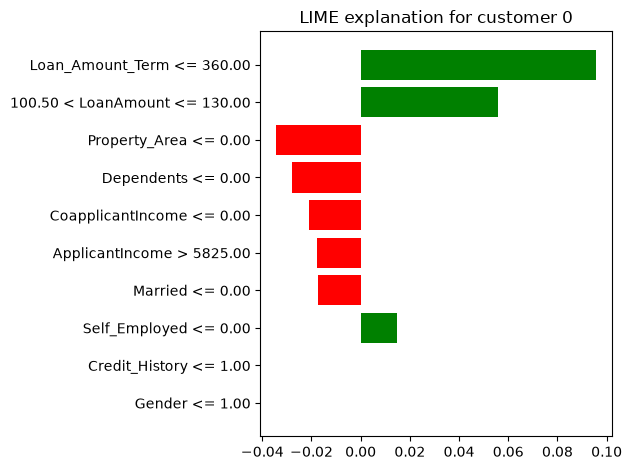

In [30]:
import lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=list(X.columns),
    class_names=['Rejected','Approved'],
    mode='classification',
    random_state=42)

lime_exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[i].values,
    predict_fn=rf_model.predict_proba)

fig = lime_exp.as_pyplot_figure()
plt.title('LIME explanation for customer ' + str(i))
plt.tight_layout()
plt.show()

In [31]:
lime_exp.as_list()

[('Loan_Amount_Term <= 360.00', 0.09563412351728506),
 ('100.50 < LoanAmount <= 130.00', 0.055665259375291286),
 ('Property_Area <= 0.00', -0.0342446445203443),
 ('Dependents <= 0.00', -0.028003642029219393),
 ('CoapplicantIncome <= 0.00', -0.021029623422028305),
 ('ApplicantIncome > 5825.00', -0.017750681113081156),
 ('Married <= 0.00', -0.017408741165825314),
 ('Self_Employed <= 0.00', 0.014719230509088941),
 ('Credit_History <= 1.00', 0.0),
 ('Gender <= 1.00', 0.0)]

## prototype - check any new customer

small function where I can type a new customer and it tells approved/rejected +
the main reasons from SHAP.

In [32]:
def check_loan_application(customer):
    new_df = pd.DataFrame([customer])[X.columns]

    pred = rf_model.predict(new_df)[0]
    prob = rf_model.predict_proba(new_df)[0]

    if pred == 1:
        print("Loan Decision : APPROVED")
        print("Confidence    :", round(prob[1]*100, 2), "%")
    else:
        print("Loan Decision : REJECTED")
        print("Confidence    :", round(prob[0]*100, 2), "%")

    # shap for this new customer
    sv = explainer(new_df)
    if len(sv.shape) == 3:
        vals = sv[0, :, 1].values
    elif len(sv.shape) == 2:
        vals = sv.values[0]
    else:
        vals = sv.values

    reasons = pd.DataFrame({'Feature': X.columns,
                            'Value': new_df.iloc[0].values,
                            'Impact': vals})
    reasons['abs'] = reasons['Impact'].abs()
    reasons = reasons.sort_values('abs', ascending=False)

    print("main reasons:")
    for _, r in reasons.head(4).iterrows():
        if r['Impact'] > 0:
            print("  ", r['Feature'], "=", r['Value'], "-> towards APPROVAL", round(r['Impact'], 3))
        else:
            print("  ", r['Feature'], "=", r['Value'], "-> towards REJECTION", round(r['Impact'], 3))
    print()


# customer 1 - good credit history, decent income
c1 = {'Gender':1, 'Married':1, 'Dependents':0, 'Education':1, 'Self_Employed':0,
      'ApplicantIncome':5500, 'CoapplicantIncome':1500, 'LoanAmount':130,
      'Loan_Amount_Term':360, 'Credit_History':1.0, 'Property_Area':1}
print("Test case 1")
check_loan_application(c1)

# customer 2 - no credit history and asking a big loan
c2 = {'Gender':1, 'Married':0, 'Dependents':2, 'Education':0, 'Self_Employed':1,
      'ApplicantIncome':2500, 'CoapplicantIncome':0, 'LoanAmount':250,
      'Loan_Amount_Term':180, 'Credit_History':0.0, 'Property_Area':0}
print("Test case 2")
check_loan_application(c2)

Test case 1
Loan Decision : APPROVED
Confidence    : 83.03 %
main reasons:
   Credit_History = 1.0 -> towards APPROVAL 0.085
   LoanAmount = 130.0 -> towards APPROVAL 0.034
   Property_Area = 1.0 -> towards APPROVAL 0.026
   ApplicantIncome = 5500.0 -> towards REJECTION -0.021

Test case 2
Loan Decision : REJECTED
Confidence    : 68.68 %
main reasons:
   Credit_History = 0.0 -> towards REJECTION -0.361
   ApplicantIncome = 2500.0 -> towards APPROVAL 0.044
   Dependents = 2.0 -> towards APPROVAL 0.032
   Education = 0.0 -> towards REJECTION -0.026



## predicting for the test.csv customers

test.csv has no Loan_Status column (thats the point), so I clean it the same way and
save the predictions to loan_predictions.csv.

In [33]:
test = pd.read_csv("test.csv")
print(test.shape)
test.head()

(367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [34]:
# same cleaning as train
ids = test['Loan_ID']
test = test.drop('Loan_ID', axis=1)

for col in ['Gender','Married','Dependents','Self_Employed','Credit_History']:
    test[col] = test[col].fillna(test[col].mode()[0])
test['LoanAmount'] = test['LoanAmount'].fillna(test['LoanAmount'].median())
test['Loan_Amount_Term'] = test['Loan_Amount_Term'].fillna(test['Loan_Amount_Term'].median())

test['Dependents'] = test['Dependents'].replace('3+', 3).astype(int)
test['Gender'] = test['Gender'].map({'Male':1, 'Female':0})
test['Married'] = test['Married'].map({'Yes':1, 'No':0})
test['Education'] = test['Education'].map({'Graduate':1, 'Not Graduate':0})
test['Self_Employed'] = test['Self_Employed'].map({'Yes':1, 'No':0})
test['Property_Area'] = test['Property_Area'].map({'Rural':0, 'Semiurban':1, 'Urban':2})

print("missing left:", test.isnull().sum().sum())

missing left: 0


In [35]:
test_pred = rf_model.predict(test)

out = pd.DataFrame({'Loan_ID': ids, 'Loan_Status': test_pred})
out['Loan_Status'] = out['Loan_Status'].map({1:'Y', 0:'N'})
out.to_csv('loan_predictions.csv', index=False)

print(out['Loan_Status'].value_counts())
out.head(10)

Loan_Status
Y    306
N     61
Name: count, dtype: int64


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y
5,LP001054,Y
6,LP001055,Y
7,LP001056,N
8,LP001059,Y
9,LP001067,Y


## Results

ok so after running everything -

**models (on the 123 test customers):**
- logistic regression - 86.18% accuracy, F1 0.908  <- best one
- SVM - 85.37%, F1 0.903
- decision tree - 84.55%, F1 0.898
- random forest - 84.55%, F1 0.898

all four are basically the same (within 1.6%), random forest is NOT better here. I still
explain the random forest because it is the black box one, that was the point of the project.

one thing I noticed - recall for "approved" is 0.99 for every model but recall for
"rejected" is only 0.53. the data is 69% approved so the models are scared to reject people.

**SHAP** said credit history is the biggest feature by far (average |shap| = 0.15, the next
one loan amount is only 0.027, so like 5-6 times bigger). then loan amount, applicant income,
property area. **LIME** said the same thing for the same customer, so both methods agree.

**prototype:**
- customer with credit history 1 + income 5500 + loan 130 -> APPROVED (83.03%), main reason credit history
- customer with credit history 0 + loan 250 -> REJECTED (68.68%), main reason credit history (-0.361)

**test.csv** -> 367 customers, model said 306 Y and 61 N, saved in loan_predictions.csv

files made by this notebook: results.csv (model comparison table), loan_predictions.csv